In [1]:
import pandas as pd 
import random 
from datetime import datetime, timedelta
from pathlib import Path
print("CareFlow project started successfully")

CareFlow project started successfully


In [2]:
import pandas as pd
import random
from datetime import datetime, timedelta
from pathlib import Path

random.seed(42)

events = []
start_date = datetime(2026, 10, 1, 8, 0)

for i in range(1, 201):
    patient_id = f"P{i:03d}"
    current_time = start_date + timedelta(
        minutes=random.randint(0, 480)
    )

    journey = [
        ("Registration", random.randint(3, 8)),
        ("Triage", random.randint(5, 15))
    ]

    if random.random() < 0.60:
        journey.append(("X-Ray", random.randint(10, 25)))

        if random.random() < 0.40:
            journey.append(("Triage", random.randint(5, 15)))

    journey.extend([
        ("Doctor Consultation", random.randint(10, 30)),
        ("Discharge", random.randint(2, 8))
    ])

    for activity, duration in journey:
        events.append({
            "Case_ID": patient_id,
            "Activity_Name": activity,
            "Timestamp": current_time
        })
        current_time += timedelta(minutes=duration)

df = pd.DataFrame(events)
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.sort_values(
    ["Case_ID", "Timestamp"]
).reset_index(drop=True)

print("Dataset generated successfully!")
print("Total patients:", df["Case_ID"].nunique())
print("Total events:", len(df))

display(df.head(10))

Dataset generated successfully!
Total patients: 200
Total events: 959


,Case_ID,Activity_Name,Timestamp
0,P001,Registration,2026-10-01 13:27:00
1,P001,Triage,2026-10-01 13:30:00
2,P001,Doctor Consultation,2026-10-01 13:35:00
3,P001,Discharge,2026-10-01 13:52:00
4,P002,Registration,2026-10-01 09:11:00
5,P002,Triage,2026-10-01 09:19:00
6,P002,Doctor Consultation,2026-10-01 09:25:00
7,P002,Discharge,2026-10-01 09:52:00
8,P003,Registration,2026-10-01 13:02:00
9,P003,Triage,2026-10-01 13:08:00


In [3]:
print(df.shape)
print(df.head())
print(df.columns)

(959, 3)
  Case_ID        Activity_Name           Timestamp
0    P001         Registration 2026-10-01 13:27:00
1    P001               Triage 2026-10-01 13:30:00
2    P001  Doctor Consultation 2026-10-01 13:35:00
3    P001            Discharge 2026-10-01 13:52:00
4    P002         Registration 2026-10-01 09:11:00
Index(['Case_ID', 'Activity_Name', 'Timestamp'], dtype='object')


In [4]:
from pathlib import Path

output_folder = Path("data/raw")
output_folder.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("data/raw/hospital_event_logs.csv")
print("Dataset saved successfully!")

Dataset saved successfully!


In [5]:
import pandas as pd

# Load the dataset
df = pd.read_csv("data/raw/hospital_event_logs.csv")

# Display the first 5 rows
print(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("Columns:", df.columns.tolist())

# Check missing values
print(df.isnull().sum())

  Case_ID        Activity_Name            Timestamp
0    P001         Registration  2026-10-01 13:27:00
1    P001               Triage  2026-10-01 13:30:00
2    P001  Doctor Consultation  2026-10-01 13:35:00
3    P001            Discharge  2026-10-01 13:52:00
4    P002         Registration  2026-10-01 09:11:00
Dataset shape: (959, 3)
Columns: ['Case_ID', 'Activity_Name', 'Timestamp']
Case_ID          0
Activity_Name    0
Timestamp        0
dtype: int64


In [6]:
# Check dataset size
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Dataset shape: (959, 3)

Column names:
['Case_ID', 'Activity_Name', 'Timestamp']

Missing values:
Case_ID          0
Activity_Name    0
Timestamp        0
dtype: int64

Duplicate rows: 0

Data types:
Case_ID          object
Activity_Name    object
Timestamp        object
dtype: object


In [7]:
# Make a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows that are completely empty
df_clean = df_clean.dropna(how="all")

# Display cleaning results
print("Original rows:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Duplicate rows removed:", len(df) - len(df_clean))

# Check remaining missing values
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Original rows: 959
Rows after cleaning: 959
Duplicate rows removed: 0

Missing values after cleaning:
Case_ID          0
Activity_Name    0
Timestamp        0
dtype: int64


In [8]:
# Display the column names
print(df_clean.columns.tolist())

['Case_ID', 'Activity_Name', 'Timestamp']


In [9]:
# Convert Timestamp column to datetime format
df_clean["Timestamp"] = pd.to_datetime(
    df_clean["Timestamp"], errors="coerce"
)

# Display the first 5 timestamps
print(df_clean[["Timestamp"]].head())

# Count invalid timestamps
print("Invalid timestamps:", df_clean["Timestamp"].isna().sum())

# Display the data types
print("\nData types:")
print(df_clean.dtypes)

            Timestamp
0 2026-10-01 13:27:00
1 2026-10-01 13:30:00
2 2026-10-01 13:35:00
3 2026-10-01 13:52:00
4 2026-10-01 09:11:00
Invalid timestamps: 0

Data types:
Case_ID                  object
Activity_Name            object
Timestamp        datetime64[ns]
dtype: object


In [10]:
# Sort records by patient ID and timestamp
df_clean = df_clean.sort_values(
    by=["Case_ID", "Timestamp"]
).reset_index(drop=True)

print(df_clean.head(10))

  Case_ID        Activity_Name           Timestamp
0    P001         Registration 2026-10-01 13:27:00
1    P001               Triage 2026-10-01 13:30:00
2    P001  Doctor Consultation 2026-10-01 13:35:00
3    P001            Discharge 2026-10-01 13:52:00
4    P002         Registration 2026-10-01 09:11:00
5    P002               Triage 2026-10-01 09:19:00
6    P002  Doctor Consultation 2026-10-01 09:25:00
7    P002            Discharge 2026-10-01 09:52:00
8    P003         Registration 2026-10-01 13:02:00
9    P003               Triage 2026-10-01 13:08:00


In [11]:
# Sort activities by patient and time
df_clean = df_clean.sort_values(
    by=["Case_ID", "Timestamp"]
).reset_index(drop=True)

# Calculate time difference between activities for each patient
df_clean["Time_Taken_Minutes"] = (
    df_clean.groupby("Case_ID")["Timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

# Display the results
print(df_clean[
    ["Case_ID", "Activity_Name", "Timestamp", "Time_Taken_Minutes"]
].head(12))

   Case_ID        Activity_Name           Timestamp  Time_Taken_Minutes
0     P001         Registration 2026-10-01 13:27:00                 NaN
1     P001               Triage 2026-10-01 13:30:00                 3.0
2     P001  Doctor Consultation 2026-10-01 13:35:00                 5.0
3     P001            Discharge 2026-10-01 13:52:00                17.0
4     P002         Registration 2026-10-01 09:11:00                 NaN
5     P002               Triage 2026-10-01 09:19:00                 8.0
6     P002  Doctor Consultation 2026-10-01 09:25:00                 6.0
7     P002            Discharge 2026-10-01 09:52:00                27.0
8     P003         Registration 2026-10-01 13:02:00                 NaN
9     P003               Triage 2026-10-01 13:08:00                 6.0
10    P003                X-Ray 2026-10-01 13:13:00                 5.0
11    P003               Triage 2026-10-01 13:29:00                16.0


In [12]:
# Calculate average time between activities
average_time = df_clean.groupby(
    "Activity_Name"
)["Time_Taken_Minutes"].mean()

print("Average time by activity:")
print(average_time.round(2))

Average time by activity:
Activity_Name
Discharge              20.03
Doctor Consultation    12.96
Registration             NaN
Triage                  7.99
X-Ray                   9.96
Name: Time_Taken_Minutes, dtype: float64


In [13]:
# Calculate average time between activities
transition_times = df_clean.groupby(
    "Activity_Name"
)["Time_Taken_Minutes"].mean()

print("Average time since the previous activity:")
print(transition_times.round(2))

Average time since the previous activity:
Activity_Name
Discharge              20.03
Doctor Consultation    12.96
Registration             NaN
Triage                  7.99
X-Ray                   9.96
Name: Time_Taken_Minutes, dtype: float64


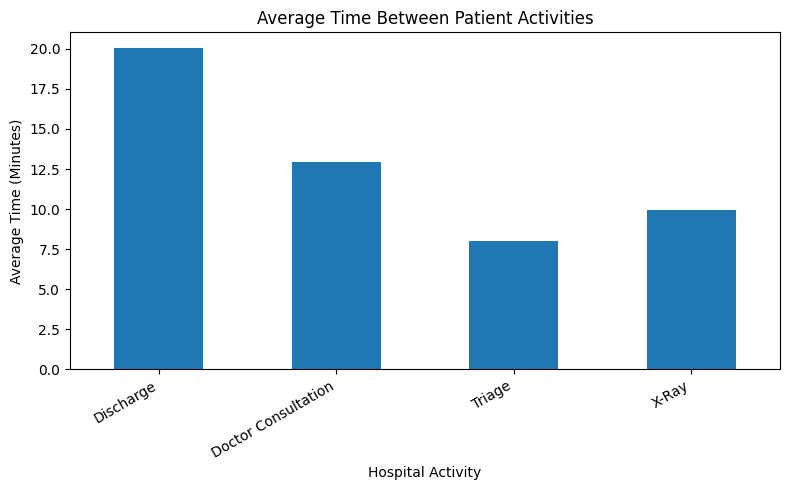

In [14]:
import matplotlib.pyplot as plt

transition_times = transition_times.dropna()

transition_times.plot(kind="bar", figsize=(8, 5))

plt.title("Average Time Between Patient Activities")
plt.xlabel("Hospital Activity")
plt.ylabel("Average Time (Minutes)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Hospital Activity Counts:
Activity_Name
Triage                 246
Registration           200
Doctor Consultation    200
Discharge              200
X-Ray                  113
Name: count, dtype: int64


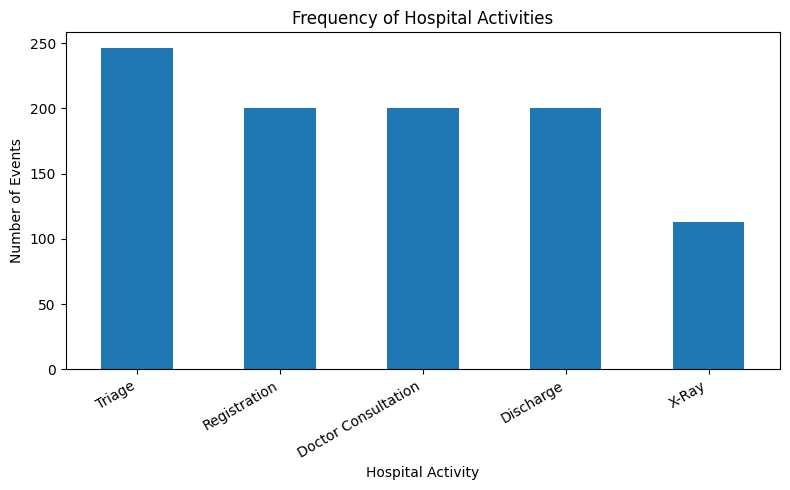

In [15]:
import matplotlib.pyplot as plt

# Count each hospital activity
activity_counts = df_clean["Activity_Name"].value_counts()

# Display the results
print("Hospital Activity Counts:")
print(activity_counts)

# Create a bar chart
activity_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Frequency of Hospital Activities")
plt.xlabel("Hospital Activity")
plt.ylabel("Number of Events")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()